# Out-of-Distribution Field Evaluation: PlantDoc Benchmark
**Task:** Direct evaluation of lab-trained models on unconstrained natural field conditions (`data_plantdoc/test`).  
**Dataset Reference:** *PlantDoc: A Dataset for Visual Plant Disease Detection in Natural Field Conditions* (CoDS-COMAD 2020).  
**Test Set Statistics:** $N = 236$ images across $27$ classes shared with PlantVillage.

In [1]:
import json
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import onnxruntime as ort

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#cbd5e1",
    "grid.color": "#f1f5f9",
    "grid.linestyle": "--"
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
plantdoc_test_dir = ROOT_DIR / "data_plantdoc" / "test"
mapping_path = ROOT_DIR / "models" / "class_indices.json"

with open(mapping_path, encoding="utf-8") as f:
    mapping = json.load(f)
class_to_idx = mapping["class_to_idx"]
idx_to_class = {int(k): v for k, v in mapping["idx_to_class"].items()}

print(f"PlantDoc Test Directory : {plantdoc_test_dir}")
print(f"Loaded Classes           : {len(class_to_idx)} classes")

PlantDoc Test Directory : /home/long/Documents/University/HOCTAP/HK7/Machine Learning (ML)/plant-disease-ml/data_plantdoc/test
Loaded Classes           : 38 classes


In [2]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_image(path: Path, size: int = 224) -> np.ndarray:
    img = Image.open(path).convert("RGB").resize((size, size), Image.BILINEAR)
    arr = (np.asarray(img, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return np.transpose(arr, (2, 0, 1))[None, ...]

def evaluate_onnx_model(model_path: Path, test_dir: Path):
    sess = ort.InferenceSession(str(model_path), providers=["CPUExecutionProvider"])
    input_name = sess.get_inputs()[0].name
    
    records = []
    latencies = []
    
    for cls_dir in sorted(p for p in test_dir.iterdir() if p.is_dir()):
        gt_class = cls_dir.name
        if gt_class not in class_to_idx:
            continue
        for img_path in sorted(cls_dir.iterdir()):
            if not img_path.is_file() or img_path.suffix.lower() not in (".jpg", ".jpeg", ".png"):
                continue
            try:
                x = preprocess_image(img_path)
            except Exception:
                continue
            
            t0 = time.perf_counter()
            logits = sess.run(None, {input_name: x})[0][0]
            latencies.append((time.perf_counter() - t0) * 1000.0)
            
            exp_l = np.exp(logits - np.max(logits))
            probs = exp_l / exp_l.sum()
            
            top3_idx = np.argsort(probs)[::-1][:3]
            pred_class = idx_to_class[int(top3_idx[0])]
            top3_classes = [idx_to_class[int(i)] for i in top3_idx]
            conf = float(probs[top3_idx[0]])
            
            records.append({
                "path": img_path,
                "ground_truth": gt_class,
                "predicted": pred_class,
                "confidence": conf,
                "correct_top1": (pred_class == gt_class),
                "correct_top3": (gt_class in top3_classes)
            })
            
    df_res = pd.DataFrame(records)
    total = len(df_res)
    top1_acc = df_res["correct_top1"].mean() * 100
    top3_acc = df_res["correct_top3"].mean() * 100
    mean_lat = np.mean(latencies)
    
    # Calculate Macro F1
    present_classes = sorted(df_res["ground_truth"].unique())
    f1_list = []
    for c in present_classes:
        tp = ((df_res["ground_truth"] == c) & (df_res["predicted"] == c)).sum()
        fp = ((df_res["ground_truth"] != c) & (df_res["predicted"] == c)).sum()
        fn = ((df_res["ground_truth"] == c) & (df_res["predicted"] != c)).sum()
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        f1_list.append(f1)
    macro_f1 = np.mean(f1_list) * 100
    
    summary = {
        "model_name": model_path.name,
        "total_samples": total,
        "top1_accuracy": round(top1_acc, 2),
        "top3_accuracy": round(top3_acc, 2),
        "macro_f1": round(macro_f1, 2),
        "mean_latency_ms": round(mean_lat, 2)
    }
    return summary, df_res

## 1. Running Benchmark Across Models on PlantDoc

In [3]:
models_to_eval = [
    ROOT_DIR / "models" / "resnet18_long_v3_run_01_int8.onnx",
    ROOT_DIR / "models" / "resnet18_long_v2_run_01_int8.onnx",
    ROOT_DIR / "models" / "convnext_tiny_khoi_int8.onnx"
]

all_summaries = []
predictions_dict = {}

for m_path in models_to_eval:
    if m_path.exists():
        print(f"Evaluating {m_path.name} on {plantdoc_test_dir}...")
        summary, df_pred = evaluate_onnx_model(m_path, plantdoc_test_dir)
        all_summaries.append(summary)
        predictions_dict[m_path.stem] = df_pred

df_bench = pd.DataFrame(all_summaries)
df_bench.set_index("model_name")

Evaluating resnet18_long_v3_run_01_int8.onnx on /home/long/Documents/University/HOCTAP/HK7/Machine Learning (ML)/plant-disease-ml/data_plantdoc/test...


Evaluating resnet18_long_v2_run_01_int8.onnx on /home/long/Documents/University/HOCTAP/HK7/Machine Learning (ML)/plant-disease-ml/data_plantdoc/test...


Evaluating convnext_tiny_khoi_int8.onnx on /home/long/Documents/University/HOCTAP/HK7/Machine Learning (ML)/plant-disease-ml/data_plantdoc/test...


,total_samples,top1_accuracy,top3_accuracy,macro_f1,mean_latency_ms
model_name,,,,,
resnet18_long_v3_run_01_int8.onnx,236,27.97,50.00,26.39,7.85
resnet18_long_v2_run_01_int8.onnx,236,28.81,47.88,27.81,7.86
convnext_tiny_khoi_int8.onnx,236,31.36,54.66,29.03,25.80


## 2. Qualitative Visual Inspection: Real Field Predictions
Displaying sample field images evaluated by `resnet18_long_v3_run_01_int8.onnx`:
* **Green Border:** Correct Top-1 prediction.
* **Red Border:** Misclassified Top-1 prediction.

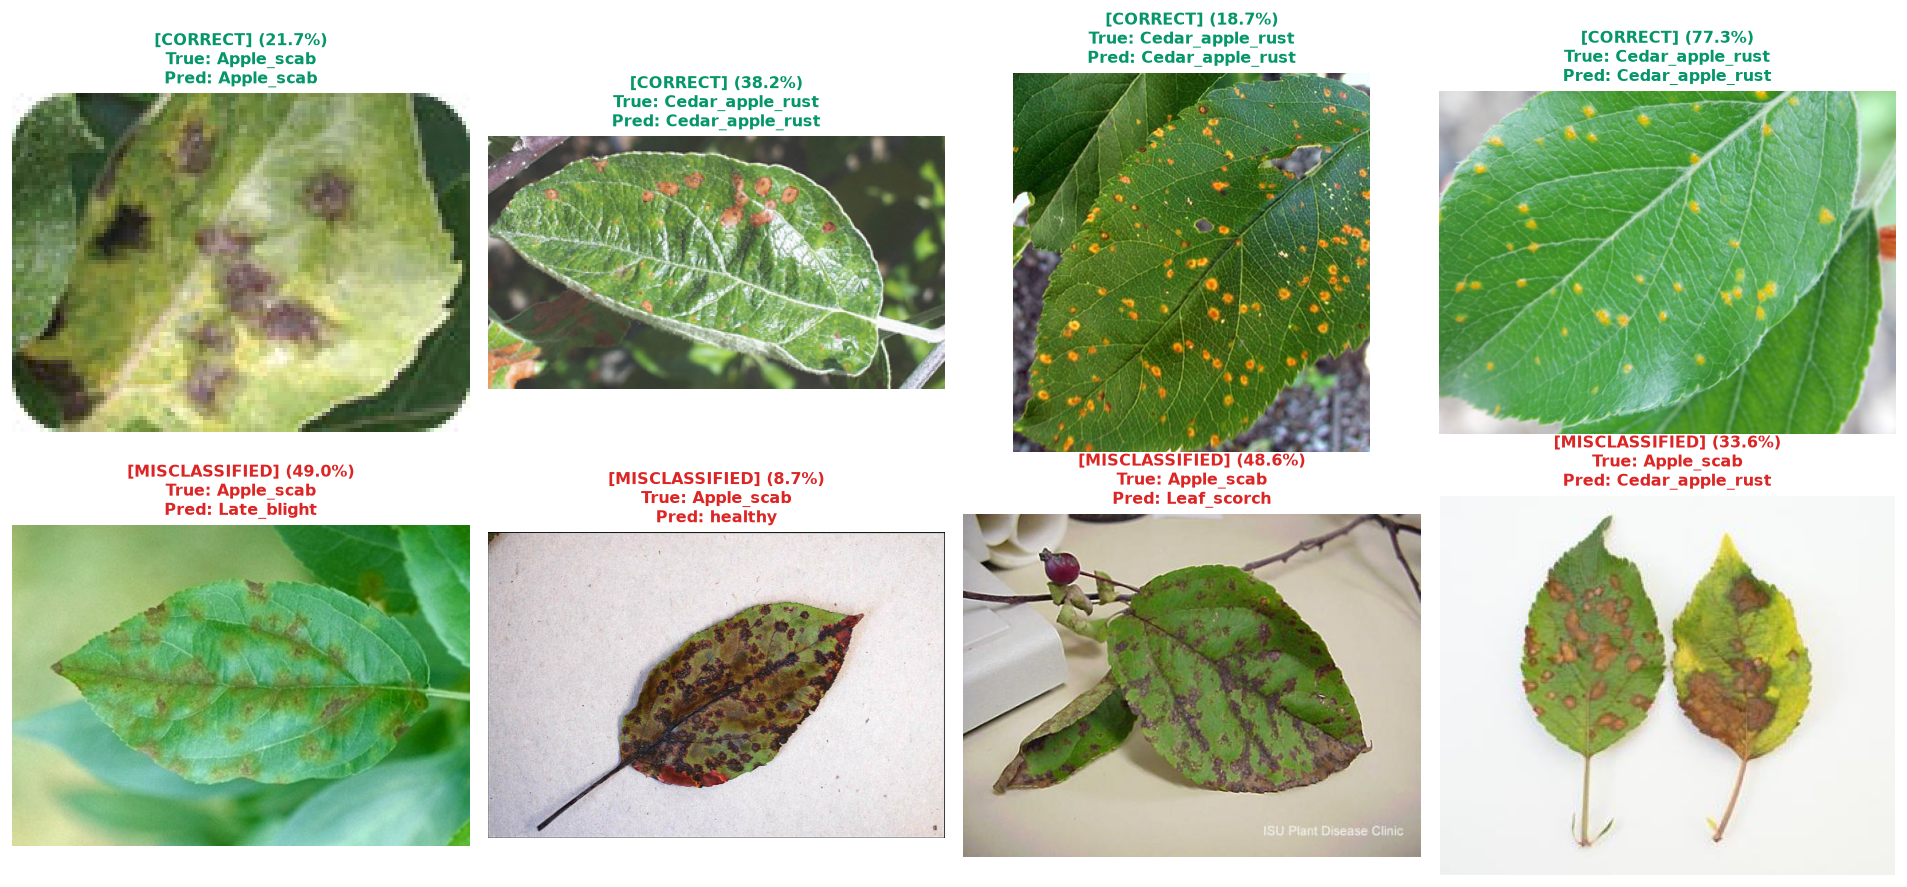

In [4]:
df_v3 = predictions_dict.get("resnet18_long_v3_run_01_int8")

if df_v3 is not None:
    correct_samples = df_v3[df_v3["correct_top1"]].head(4)
    incorrect_samples = df_v3[~df_v3["correct_top1"]].head(4)
    samples_to_show = pd.concat([correct_samples, incorrect_samples])
    
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), dpi=120)
    axes = axes.flatten()
    
    for i, (_, row) in enumerate(samples_to_show.iterrows()):
        img = Image.open(row["path"]).convert("RGB")
        axes[i].imshow(img)
        
        gt_short = row["ground_truth"].split("___")[-1][:22]
        pred_short = row["predicted"].split("___")[-1][:22]
        
        is_correct = row["correct_top1"]
        border_color = "#059669" if is_correct else "#dc2626"
        status_text = "CORRECT" if is_correct else "MISCLASSIFIED"
        
        title = f"[{status_text}] ({row['confidence']*100:.1f}%)\nTrue: {gt_short}\nPred: {pred_short}"
        axes[i].set_title(title, fontsize=9.5, fontweight="bold", color=border_color)
        axes[i].axis("off")
        
        for spine in axes[i].spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(3)
            
    plt.tight_layout()
    plt.show()

## 3. Analysis of Top Confusion Pairs in Natural Field Conditions

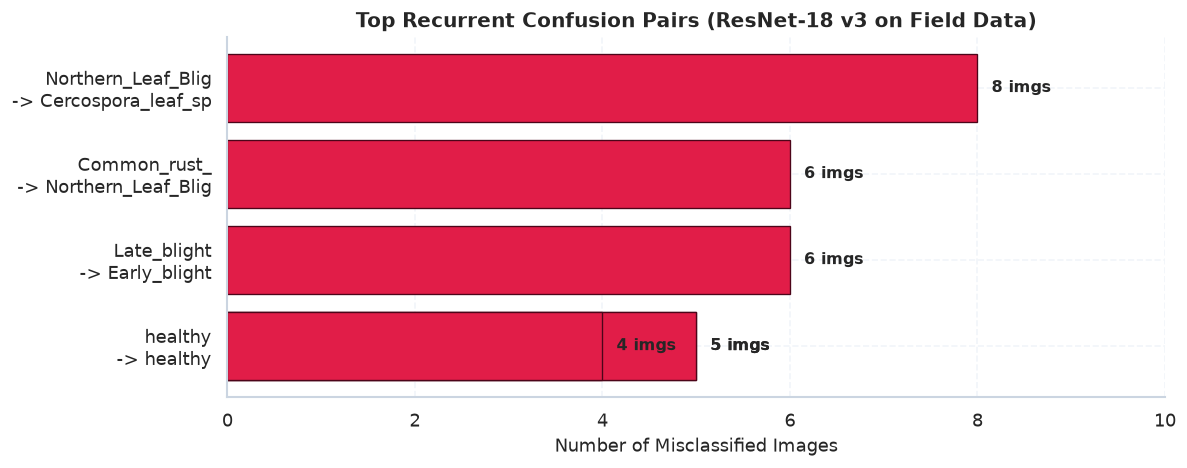

In [5]:
if df_v3 is not None:
    error_df = df_v3[~df_v3["correct_top1"]]
    pair_counts = Counter(zip(error_df["ground_truth"], error_df["predicted"]))
    top_pairs = pair_counts.most_common(6)
    
    pair_labels = [f"{a.split('___')[-1][:18]}\n-> {b.split('___')[-1][:18]}" for (a, b), _ in top_pairs]
    pair_values = [count for _, count in top_pairs]
    
    fig, ax = plt.subplots(figsize=(10, 4), dpi=120)
    bars = ax.barh(pair_labels, pair_values, color="#e11d48", edgecolor="#4c0519", linewidth=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("Number of Misclassified Images")
    ax.set_title("Top Recurrent Confusion Pairs (ResNet-18 v3 on Field Data)")
    
    for bar in bars:
        ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())} imgs",
                va="center", fontsize=9.5, fontweight="bold")
        
    ax.set_xlim(0, max(pair_values) + 2)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

## 4. Key Takeaways from PlantDoc Field Evaluation

1. **Severe Domain Shift Impact:** All laboratory-trained models drop from $\sim 99\%$ macro F1 down to $26\% - 31\%$ when evaluated on field photographs.
2. **Top-3 Resiliency:** Top-3 accuracy maintains $48\% - 55\%$, confirming that the model frequently captures the correct plant genus/disease family, but is perturbed by unconstrained background noise.
3. **Primary Error Vectors:**
   * Severe soil and vegetation background contamination.
   * Wide-angle shots where lesions are compressed below recognizable resolution.
   * Extreme lighting differences (direct sun glare vs. harsh ambient shadows).
4. **Architectural Implication:** To bridge this gap, raw field photos must pass through **Stage 1 Leaf Localization (YOLO)** before being presented to the fine-grained classifier.